# Annual PoR cluster balance from the original ITOM files

This standalone workflow reads actual process operation in CL/OCE and constructs an annual cluster inventory without purchasing allocated internal PoR intermediates. The complete syngas network includes biomass gasification.

The functional unit is **one year of the modelled conversion cluster supplying its complete output basket and exports**. The selected polymer basket is displayed for comparison. Attributing all ITOM process activity to that smaller basket would require additional assumptions about coproducts and exports.

Default execution builds physical ledgers and review tables. The optional background LCA requires reviewed suppliers and emission coverage. Existing workflows, workbooks and databases are not modified.


In [11]:
from pathlib import Path
from datetime import datetime, timezone
import json
import hashlib
import os
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / "scenario_data").is_dir():
    matches = [p for p in ROOT.parents if (p / "scenario_data").is_dir()]
    if not matches:
        raise FileNotFoundError("Start this notebook from the repository.")
    ROOT = matches[0]
dll_handles = []
dll_dir = Path(sys.prefix) / "Library/bin"
if os.name == "nt" and dll_dir.is_dir():
    os.environ["PATH"] = str(dll_dir) + os.pathsep + os.environ.get("PATH", "")
    dll_handles.append(os.add_dll_directory(str(dll_dir)))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

WORKBOOKS = {
    "CL": ROOT / "scenario_data/TRANSIENCE-WP8_ITOM-petchem_data_CL-scenario_2026-04-15.xlsx",
    "OCE": ROOT / "scenario_data/TRANSIENCE-WP8_ITOM-petchem_data_OCE-scenario_2026-08-19.xlsx",
}
SCENARIOS = ["CL", "OCE"]
YEARS = [2050]
LOCATION = "Rotterdam"
REGION = "NL"
PERIOD_YEARS = 5.0
TOLERANCE = 1e-6
SAVE_OUTPUTS = False
RUN_BACKGROUND_LCIA = True
OUTPUT_DIR = ROOT / "results/cluster_balance"
# Allowed overrides: "inside" or "external_supply".
BOUNDARY_OVERRIDES = {}
ENERGY = {"electricity", "steam", "HT_heat"}
CO2 = {"flue_gas_CO2", "unavoidable_CO2", "uncompressed_CO2", "stored_CO2"}
BOOKKEEPING = {"CO2_allowance", "CO2_allowances", "avoided_incineration_CO2"}
SELECTED_PRODUCTS = {"MDI", "PET", "polypropylene", "nylon_6_6", "polyols",
                     "PLA", "PBS", "PMMA", "polyvinyl_chloride"}

# OCE volume sheets contain technologies absent from its inherited technology list.
# Explicit supplemental classifications are reported as such in the boundary table.
SUPPLEMENTAL_TYPES = {
    "butanediol_from_sugar": "conversion",
    "adipic_acid_from_sugar": "conversion",
    "PTA_from_sugar": "conversion",
    "ethylene_from_ethanol": "conversion",
    "CCS_uncompressed_CO2": "CO2-related",
    "plastic_waste_pyrolysis_ETICS": "conversion",
    **{f"gasification_of_plastic_waste_FB_{suffix}": "conversion"
       for suffix in ("3b", "6a", "7b", "11b", "12b")},
    **{f"waste_production_{suffix}": "material input"
       for suffix in ("ETICS", "PA", "agriotherthermo")},
}


## 1. Source definitions and system boundary

The workbook INFO sheets define volume data as kt or TJ per five-year step. Divide volume sheets once by five, leaving capacity and process coefficients unchanged.

Material-input technologies and terminals are supply interfaces at ITOM's boundary. They and hydrogen_supply are outside this notebook's conversion system. Their outputs need upstream provider inventories. Their own input rows are excluded to avoid duplication with those providers. Other technologies, including conversion, heat recovery and CCS, are inside. Review the editable boundary table before interpreting results.

The source notes explicitly identify steam and CO2 accounting attached to waste_production as financial constructs. They are filtered, with the removed rows retained for audit. External supplies can still contain allocation in the background database.

The OCE volume sheets include technologies absent from its technology list. Explicit supplemental classifications are shown in the boundary review. Dummy substitution activities map PLA/PBS into demand-equivalent services. Their input/output records are audited separately, preserving the actual resin as the physical basket output without adding avoided-production credits.


In [12]:
SHEETS = ["INFO", "products", "technologies", "production_volume", "use_volume",
          "input_factors", "output_factors", "transport_to_PoR", "transport_from_PoR",
          "transport_within_PoR"]
source, provenance, boundary_records = {}, [], []
for scenario in SCENARIOS:
    path = WORKBOOKS[scenario]
    source[scenario] = pd.read_excel(path, sheet_name=SHEETS)
    provenance.append(dict(scenario=scenario, path=str(path),
                           sha256=hashlib.sha256(path.read_bytes()).hexdigest()))
    info = source[scenario]["INFO"].fillna("").astype(str).agg(" ".join, axis=1)
    display(info[info.str.contains("units|temporal resolution|waste_production", case=False)]
            .rename(scenario + " source notes").to_frame())
    technologies = source[scenario]["technologies"].dropna(subset=["TECHNOLOGY"])
    if technologies.TECHNOLOGY.duplicated().any():
        raise ValueError("Duplicate technology definitions.")

    listed = set(technologies.TECHNOLOGY)
    present = set()
    for sheet in ("production_volume", "use_volume"):
        present.update(source[scenario][sheet].TECHNOLOGY)
    missing = present - listed
    additions = []
    for technology in sorted(missing):
        kind = ("demand conversion" if technology.startswith("subst_with_")
                else SUPPLEMENTAL_TYPES.get(technology))
        if kind is None:
            raise ValueError(f"Unclassified technology in {scenario}: {technology}")
        additions.append({"TECHNOLOGY": technology, "type": kind})
    if additions:
        display(pd.DataFrame(additions).assign(scenario=scenario,
            classification_source="explicit supplement; absent from source technology list"))
        technologies = pd.concat([technologies, pd.DataFrame(additions)], ignore_index=True)
    for row in technologies.itertuples(index=False):
        external = row.type in {"material input", "terminal"} or row.TECHNOLOGY == "hydrogen_supply"
        boundary = BOUNDARY_OVERRIDES.get(row.TECHNOLOGY, "external_supply" if external else "inside")
        if boundary not in {"inside", "external_supply"}:
            raise ValueError("Invalid boundary override.")
        boundary_records.append(dict(scenario=scenario, technology=row.TECHNOLOGY,
                                     source_type=row.type, boundary=boundary))
boundary_table = pd.DataFrame(boundary_records)
display(boundary_table.groupby(["scenario", "source_type", "boundary"]).size().rename("technologies").to_frame())
display(boundary_table[boundary_table.boundary.eq("external_supply")])


,CL source notes
7,units production_volume: kt or TJ / time step
17,temporal resolution 5 year time steps For prod...
24,"NOTES: regarding the functional unit, see e..."
26,input_factors quantity of input products per ...
27,output_factors quantity of input products per...
65,NOTES waste_production technologies The inputs...


,OCE source notes
7,units production_volume: kt or TJ / time step
17,temporal resolution 5 year time steps For prod...
24,"NOTES: regarding the functional unit, see e..."
26,input_factors quantity of input products per ...
27,output_factors quantity of input products per...
65,NOTES waste_production technologies The inputs...


,TECHNOLOGY,type,scenario,classification_source
0,CCS_uncompressed_CO2,CO2-related,OCE,explicit supplement; absent from source techno...
1,PTA_from_sugar,conversion,OCE,explicit supplement; absent from source techno...
2,adipic_acid_from_sugar,conversion,OCE,explicit supplement; absent from source techno...
3,butanediol_from_sugar,conversion,OCE,explicit supplement; absent from source techno...
4,ethylene_from_ethanol,conversion,OCE,explicit supplement; absent from source techno...
5,gasification_of_plastic_waste_FB_11b,conversion,OCE,explicit supplement; absent from source techno...
6,gasification_of_plastic_waste_FB_12b,conversion,OCE,explicit supplement; absent from source techno...
7,gasification_of_plastic_waste_FB_3b,conversion,OCE,explicit supplement; absent from source techno...
8,gasification_of_plastic_waste_FB_6a,conversion,OCE,explicit supplement; absent from source techno...
9,gasification_of_plastic_waste_FB_7b,conversion,OCE,explicit supplement; absent from source techno...


technologies
scenario source_type                  boundary                     
CL       CO2-related                  inside                      3
         HVC, intermediates, polymers external_supply             1
                                      inside                     59
         energy input                 inside                      1
         material input               external_supply            18
         terminal                     external_supply             7
OCE      CO2-related                  inside                      4
         HVC, intermediates, polymers external_supply             1
                                      inside                     59
         conversion                   inside                     10
         demand conversion            inside                      7
         energy input                 inside                      1
         material input               external_supply            21
         terminal                     external_supply             7

,scenario,technology,source_type,boundary
25,CL,hydrogen_supply,"HVC, intermediates, polymers",external_supply
64,CL,agricultural_residue_production,material input,external_supply
65,CL,atmospheric_crude_oil_distillation_default,material input,external_supply
66,CL,chlorine_production_BAT,material input,external_supply
67,CL,energy_crops_production,material input,external_supply
68,CL,FCC_propylene_dedicated_default,material input,external_supply
69,CL,FT_distillation_LT_default,material input,external_supply
70,CL,lignocellulosic_residue_production,material input,external_supply
71,CL,waste_production_agric-m,material input,external_supply
72,CL,waste_production_autoc-m,material input,external_supply


## 2. Annual physical ledgers

Production and consumption already describe actual operation by mode. Each process is counted once, with all its outputs. Internal transport records are diagnostic and are not added a second time. Border imports/exports and terminal supply interfaces remain distinct until overlap has been reviewed.


In [13]:
records, borders, removed = [], [], []
for scenario, sheets in source.items():
    boundary = boundary_table[boundary_table.scenario.eq(scenario)].set_index("technology").boundary
    for sheet, value, direction in [
        ("production_volume", "LocalProductionByMode", "output"),
        ("use_volume", "LocalUseByMode", "input"),
    ]:
        raw = sheets[sheet]
        if not set(YEARS) <= set(raw.loc[raw.LOCATION.eq(LOCATION), "YEAR"]):
            raise ValueError(f"{scenario}/{sheet}: requested years missing.")
        frame = raw.loc[raw.LOCATION.eq(LOCATION) & raw.YEAR.isin(YEARS)].copy()
        keys = ["LOCATION", "TECHNOLOGY", "PRODUCT", "MODE_OF_OPERATION", "YEAR"]
        if frame.duplicated(keys).any():
            raise ValueError("Duplicate process coordinates.")
        frame = frame.rename(columns={"TECHNOLOGY":"technology", "PRODUCT":"product",
                                      "MODE_OF_OPERATION":"mode", "YEAR":"year"})
        frame["quantity"] = pd.to_numeric(frame[value], errors="raise") / PERIOD_YEARS
        if not np.isfinite(frame.quantity).all() or frame.quantity.lt(0).any():
            raise ValueError("Invalid physical quantities.")
        frame["scenario"], frame["direction"] = scenario, direction
        frame["unit"] = np.where(frame["product"].isin(ENERGY), "TJ/year", "kt/year")
        financial = frame["product"].isin(BOOKKEEPING) | (
            frame.technology.str.startswith("waste_production_") & frame["product"].eq("steam"))

        # These map alternative resin to a demand-equivalent service. Preserve the
        # actual resin as an output and audit the service mapping separately.
        service = frame.technology.str.startswith("subst_with_")
        if direction == "input" and frame.loc[service, "product"].isin({"PLA", "PBS"}).eq(False).any():
            raise ValueError("Demand-conversion activity has unexpected physical inputs.")
        if direction == "output" and not frame.loc[service, "product"].str.endswith("_demand").all():
            raise ValueError("Demand-conversion activity has unexpected outputs.")
        financial = financial | service
        frame["exclusion_reason"] = np.where(service, "demand-equivalent service mapping", "financial bookkeeping")
        removed.append(frame.loc[financial].copy())
        frame = frame.loc[~financial].copy()
        frame["boundary"] = frame.technology.map(boundary)
        if frame.boundary.isna().any():
            raise ValueError("Unknown boundary technology.")
        records.append(frame[["scenario","year","technology","mode","product",
                              "direction","quantity","unit","boundary"]])
    for sheet, direction, location_field in [
        ("transport_to_PoR","import","LOCATION_2"),
        ("transport_from_PoR","export","LOCATION_1"),
    ]:
        frame = sheets[sheet]
        frame = frame.loc[frame[location_field].eq(LOCATION) & frame.YEAR.isin(YEARS)].copy()
        frame = frame.rename(columns={"PRODUCT":"product", "YEAR":"year"})
        frame["quantity"] = pd.to_numeric(frame.Transport, errors="raise") / PERIOD_YEARS
        if not np.isfinite(frame.quantity).all() or frame.quantity.lt(0).any():
            raise ValueError("Invalid border flow.")
        frame["scenario"], frame["direction"] = scenario, direction
        frame["unit"] = np.where(frame["product"].isin(ENERGY), "TJ/year", "kt/year")
        borders.append(frame[["scenario","year","product","quantity","direction","unit",
                              "LOCATION_1","LOCATION_2","TRANSPORTMODE"]])
ledger = pd.concat(records, ignore_index=True)
trade = pd.concat(borders, ignore_index=True)
filtered_bookkeeping = pd.concat(removed, ignore_index=True)
display(filtered_bookkeeping.groupby(["scenario","product","direction"]).quantity.sum().to_frame())


quantity
scenario product                                        direction              
CL       CO2_allowance                                  input       1727.108650
                                                        output      1727.108650
         avoided_incineration_CO2                       input       3193.964411
                                                        output      3193.964411
         steam                                          input      37533.374008
OCE      CO2_allowance                                  input       1835.593312
                                                        output      1835.593312
         PLA                                            input        100.630034
         avoided_incineration_CO2                       input       2792.826481
                                                        output      2792.826481
         expanded_polystyrene_EPS_demand                output        62.090872
         polyethylene_LDPE_and_LLDPE_agriculture_demand output         2.041563
         polyethylene_LDPE_and_LLDPE_packaging_demand   output        36.497599
         steam                                          input      37011.696708

## 3. Product balance, final demand and external utilities

For each product, residual = production + imports - use - exports. A positive residual of a final-output product is domestic final demand. Its exports are recorded separately, so exported polymers are counted once. All intermediate exports also belong to the annual output basket. Other material residuals require clarification and are not converted into assumed purchases or sales.

Physical utility procurement is included-process consumption + exports - included generation, bounded at zero. This removes financial steam demand from the physical calculation. It assumes local heat can meet demand of the same ITOM class first. Temperature, pressure, timing and network constraints require review. Reported purchases remain visible alongside this estimate.


In [14]:
balances, baskets, utilities, co2_records = [], [], [], []
for scenario, sheets in source.items():
    types = sheets["products"].dropna(subset=["PRODUCT"]).set_index("PRODUCT")["type"]
    if types.index.duplicated().any():
        raise ValueError("Duplicate product definitions.")
    for year in YEARS:
        frame = ledger.loc[ledger.scenario.eq(scenario) & ledger.year.eq(year)]
        border = trade.loc[trade.scenario.eq(scenario) & trade.year.eq(year)]
        flows = frame.groupby(["product","direction"]).quantity.sum().unstack(fill_value=0)
        flows = flows.reindex(columns=["output","input"], fill_value=0)
        transfers = border.groupby(["product","direction"]).quantity.sum().unstack(fill_value=0)
        transfers = transfers.reindex(columns=["import","export"], fill_value=0)
        table = flows.join(transfers, how="outer").fillna(0)
        table["residual"] = table.output + table["import"] - table.input - table["export"]
        scale = table[["output","input","import","export"]].abs().max(axis=1)
        table["balanced"] = table.residual.abs().le(TOLERANCE + scale * 1e-8)
        table["product_type"] = table.index.map(types)
        table["unit"] = np.where(table.index.isin(ENERGY), "TJ/year", "kt/year")
        table["status"] = np.where(table.balanced, "balanced", "unresolved")
        table.loc[table.index.isin(ENERGY), "status"] = "utility_review"
        table.loc[table.index.isin(CO2), "status"] = "CO2_review"
        final = table.product_type.eq("outputs")
        table.loc[final & table.residual.ge(-TOLERANCE), "status"] = "domestic_final_demand"
        table["scenario"], table["year"] = scenario, year
        balances.append(table.reset_index())
        basket = table.loc[final].copy()
        basket["domestic_final_demand"] = basket.residual.clip(lower=0)
        basket["final_product_exports"] = basket["export"]
        basket["basket_quantity"] = basket.domestic_final_demand + basket.final_product_exports
        basket["selected_reference"] = basket.index.isin(SELECTED_PRODUCTS)
        baskets.append(basket.reset_index())
        inside = frame.loc[frame.boundary.eq("inside")]
        for product in sorted(ENERGY):
            produced = inside.loc[inside["product"].eq(product) & inside.direction.eq("output"), "quantity"].sum()
            consumed = inside.loc[inside["product"].eq(product) & inside.direction.eq("input"), "quantity"].sum()
            exported = border.loc[border["product"].eq(product) & border.direction.eq("export"), "quantity"].sum()
            reported = border.loc[border["product"].eq(product) & border.direction.eq("import"), "quantity"].sum()
            reported += frame.loc[frame.boundary.eq("external_supply") & frame["product"].eq(product)
                                   & frame.direction.eq("output"), "quantity"].sum()
            net = consumed + exported - produced
            if abs(net) <= TOLERANCE + 1e-8 * max(consumed, produced, exported):
                net = 0.0
            utilities.append(dict(scenario=scenario, year=year, product=product, unit="TJ/year",
                internal_generation=produced, physical_consumption=consumed,
                reported_purchase=reported, physical_purchase=max(net,0),
                unassigned_surplus=max(-net,0), procurement_adjustment=max(net,0)-reported))
        for product in sorted(CO2):
            produced = inside.loc[inside["product"].eq(product) & inside.direction.eq("output"), "quantity"].sum()
            consumed = inside.loc[inside["product"].eq(product) & inside.direction.eq("input"), "quantity"].sum()
            co2_records.append(dict(scenario=scenario, year=year, product=product,
                production_kt=produced, internal_use_kt=consumed, residual_kt=produced-consumed,
                destination="captured_destination_review" if product=="stored_CO2" else "candidate_release"))
product_balance = pd.concat(balances, ignore_index=True)
final_basket = pd.concat(baskets, ignore_index=True)
utility_balance = pd.DataFrame(utilities)
co2_balance = pd.DataFrame(co2_records)
unresolved = product_balance.loc[product_balance.status.eq("unresolved")]
exported_products = trade.loc[trade.direction.eq("export")].groupby(
    ["scenario","year","product","unit"], as_index=False).quantity.sum()
display(final_basket[["scenario","year","product","domestic_final_demand","final_product_exports",
                     "basket_quantity","selected_reference"]])
display(exported_products)
display(unresolved[["scenario","year","product","residual","unit"]])
display(utility_balance.round(3))


direction,scenario,year,product,domestic_final_demand,final_product_exports,basket_quantity,selected_reference
0,CL,2050,MDI,0.000000,23.957807,23.957807,True
1,CL,2050,PBR,30.000000,0.000000,30.000000,False
2,CL,2050,PBS,17.260478,0.000000,17.260478,True
3,CL,2050,PET,0.000000,410.000000,410.000000,True
4,CL,2050,PMMA,23.000000,0.000000,23.000000,True
5,CL,2050,nylon_6_6,24.422824,62.135872,86.558696,True
6,CL,2050,polyols,41.384322,0.000000,41.384322,True
7,CL,2050,polypropylene,180.000000,0.000000,180.000000,True
8,CL,2050,polyvinyl_chloride,450.000000,0.000000,450.000000,True
9,OCE,2050,MDI,377.885382,0.000000,377.885382,True


,scenario,year,product,unit,quantity
0,CL,2050,FT_naphtha,kt/year,421.471287
1,CL,2050,MDI,kt/year,23.957807
2,CL,2050,PET,kt/year,410.000000
3,CL,2050,PET_waste,kt/year,81.955161
4,CL,2050,PTA,kt/year,47.940716
5,CL,2050,autoc-m_waste,kt/year,8.257251
6,CL,2050,butadiene,kt/year,4.929133
7,CL,2050,ethane,kt/year,130.856692
8,CL,2050,ethylene,kt/year,516.007865
9,CL,2050,formaldehyde,kt/year,112.064755


direction,scenario,year,product,residual,unit
31,CL,2050,ethylene_oxide,74.641411,kt/year
35,CL,2050,isopropanol,103.759233,kt/year
39,CL,2050,methanol,1.000000,kt/year
104,OCE,2050,isopropanol,103.759233,kt/year
112,OCE,2050,para_xylene,1.000000,kt/year
117,OCE,2050,propylene,1.000000,kt/year
127,OCE,2050,syngas_CO,159.787029,kt/year


,scenario,year,product,unit,internal_generation,physical_consumption,reported_purchase,physical_purchase,unassigned_surplus,procurement_adjustment
0,CL,2050,HT_heat,TJ/year,6281.038,6281.038,0.000,0.000,-0.0,0.000
1,CL,2050,electricity,TJ/year,20.110,7704.176,8262.254,7684.065,0.0,-578.189
2,CL,2050,steam,TJ/year,7031.613,23904.005,54442.935,16872.392,0.0,-37570.543
3,OCE,2050,HT_heat,TJ/year,8565.164,8565.164,0.000,0.000,-0.0,0.000
4,OCE,2050,electricity,TJ/year,9.000,10503.581,16915.541,10494.581,0.0,-6420.960
5,OCE,2050,steam,TJ/year,9403.014,26151.840,54173.299,16748.826,0.0,-37424.473


## 4. Independent check of process activity

Actual inputs and outputs divided by their coefficients should imply a common activity level for a technology and mode. This checks source consistency without multiplying quantities into the inventory again. Select one factor region explicitly. Missing factors and inconsistent ratios remain visible.


In [15]:
FACTOR_REGION = "West"
checks, factor_gaps = [], []
for scenario, sheets in source.items():
    for direction, sheet, factor_column in [
        ("input","input_factors","InputActivityRatio"),
        ("output","output_factors","OutputActivityRatio"),
    ]:
        factors = sheets[sheet].loc[sheets[sheet].YEAR.isin(YEARS)].copy()
        if "REGION" in factors:
            factors = factors.loc[factors.REGION.eq(FACTOR_REGION)]
        factors = factors.rename(columns={"TECHNOLOGY":"technology","PRODUCT":"product",
            "MODE_OF_OPERATION":"mode","YEAR":"year",factor_column:"coefficient"})
        keys = ["technology","product","mode","year"]
        if factors.duplicated(keys).any():
            raise ValueError("Ambiguous process coefficients.")
        actual = ledger.loc[ledger.scenario.eq(scenario) & ledger.direction.eq(direction)
                            & ledger.boundary.eq("inside")]
        comparison = actual.merge(factors[keys+["coefficient"]], on=keys, how="left")
        factor_gaps.append(comparison.loc[comparison.coefficient.isna()])
        valid = comparison.loc[comparison.coefficient.gt(0)].copy()
        valid["activity"] = valid.quantity / valid.coefficient
        checks.append(valid)
activity_detail = pd.concat(checks, ignore_index=True)
activity_checks = activity_detail.groupby(["scenario","year","technology","mode"]).activity.agg(
    minimum="min", maximum="max", median="median", matched_flows="count").reset_index()
activity_checks["relative_spread"] = (
    (activity_checks.maximum-activity_checks.minimum) / activity_checks["median"].abs().clip(lower=1e-12))
activity_checks["consistent"] = activity_checks.relative_spread.le(1e-5)
missing_factors = pd.concat(factor_gaps, ignore_index=True)
display(activity_checks.loc[~activity_checks.consistent])
display(missing_factors[["scenario","year","technology","product","direction"]].head(20))


,scenario,year,technology,mode,minimum,maximum,median,matched_flows,relative_spread,consistent


,scenario,year,technology,product,direction


## 5. Direct CO2 and one annual cluster inventory

Residual flue CO2, unavoidable CO2 and uncompressed CO2 represent candidate atmospheric releases after internal capture/reuse. Captured stored_CO2 is kept separate and is never subtracted again from actual releases. ITOM's field can mean captured/compressed CO2 awaiting transport and storage. Destination and downstream service burdens need review.

Carbon origin and non-CO2 pollutants are unresolved. Do not relabel all direct CO2 fossil or add an atmospheric uptake credit without tracing the carbon and checking the selected method.

External source-interface outputs, explicit material imports and net utility purchases enter the annual service inventory. The full output basket includes final products and intermediate exports. No automatic substitution credits are applied. Add missing residual water, oxygen, catalysts, infrastructure, logistics and storage burdens through the editable list, avoiding overlap with upstream supply inventories.


In [16]:
if co2_balance.residual_kt.lt(-TOLERANCE).any():
    raise ValueError("CO2 use exceeds included production. Review the boundary.")
direct_co2 = co2_balance.loc[co2_balance.destination.eq("candidate_release")].groupby(
    ["scenario","year"]).residual_kt.sum().rename("direct_CO2_kt").reset_index()
display(co2_balance.round(3))
display(direct_co2.round(3))

# Optional records: scenario, year, source_id, product, quantity, unit, evidence.
ADDITIONAL_EXTERNAL_EXCHANGES = []
external = []
for row in ledger.loc[ledger.boundary.eq("external_supply") & ledger.direction.eq("output")
                      & ~ledger["product"].isin(ENERGY | CO2)].itertuples(index=False):
    if row.quantity > 0:
        external.append(dict(scenario=row.scenario,year=row.year,source_id="supply:"+row.technology,
            product=row.product,quantity=row.quantity,unit=row.unit,evidence="ITOM source interface"))
for row in trade.loc[trade.direction.eq("import")
                     & ~trade["product"].isin(ENERGY | CO2 | BOOKKEEPING)].itertuples(index=False):
    if row.quantity > 0:
        external.append(dict(scenario=row.scenario,year=row.year,
            source_id=f"import:{row.LOCATION_1}:{row.TRANSPORTMODE}",product=row.product,
            quantity=row.quantity,unit=row.unit,evidence="ITOM border import"))
for row in utility_balance.itertuples(index=False):
    if row.physical_purchase > 0:
        external.append(dict(scenario=row.scenario,year=row.year,source_id="utility:net",
            product=row.product,quantity=row.physical_purchase,unit=row.unit,
            evidence="Physical utility demand minus generation"))
external.extend(ADDITIONAL_EXTERNAL_EXCHANGES)
external_inventory = pd.DataFrame(external)
if not np.isfinite(external_inventory.quantity).all() or external_inventory.quantity.le(0).any():
    raise ValueError("External quantities must be finite and positive.")
external_inventory = external_inventory.groupby(
    ["scenario","year","source_id","product","unit","evidence"],as_index=False).quantity.sum()
annual_inventories = {}
for scenario in SCENARIOS:
    for year in YEARS:
        annual_inventories[f"{scenario}_{year}"] = {
            "name": f"PoR annual conversion-cluster basket, {scenario}, {year}",
            "reference product":"annual cluster production service","unit":"unit",
            "production amount":1,"location":REGION,
            "external_inputs":external_inventory.loc[external_inventory.scenario.eq(scenario)
                & external_inventory.year.eq(year)].to_dict("records"),
            "direct_CO2_origin_unresolved_kg":float(direct_co2.loc[direct_co2.scenario.eq(scenario)
                & direct_co2.year.eq(year),"direct_CO2_kt"].iloc[0]*1e6),
            "final_products":final_basket.loc[final_basket.scenario.eq(scenario)
                & final_basket.year.eq(year),["product","domestic_final_demand",
                "final_product_exports","basket_quantity","unit"]].to_dict("records"),
            "all_product_exports":exported_products.loc[exported_products.scenario.eq(scenario)
                & exported_products.year.eq(year)].to_dict("records"),
            "captured_CO2_destination_review":co2_balance.loc[co2_balance.scenario.eq(scenario)
                & co2_balance.year.eq(year) & co2_balance["product"].eq("stored_CO2")].to_dict("records"),
            "unresolved_product_flows":unresolved.loc[unresolved.scenario.eq(scenario)
                & unresolved.year.eq(year),["product","residual","unit"]].to_dict("records"),
            "status":"physical inventory awaiting provider and completeness review",
        }
display(external_inventory)


,scenario,year,product,production_kt,internal_use_kt,residual_kt,destination
0,CL,2050,flue_gas_CO2,1706.803,1706.803,-0.000,candidate_release
1,CL,2050,stored_CO2,2216.021,0.000,2216.021,captured_destination_review
2,CL,2050,unavoidable_CO2,191.158,0.000,191.158,candidate_release
3,CL,2050,uncompressed_CO2,223.026,223.026,0.000,candidate_release
4,OCE,2050,flue_gas_CO2,1787.508,0.000,1787.508,candidate_release
5,OCE,2050,stored_CO2,1022.875,0.000,1022.875,captured_destination_review
6,OCE,2050,unavoidable_CO2,48.580,0.000,48.580,candidate_release
7,OCE,2050,uncompressed_CO2,30.581,30.581,0.000,candidate_release


,scenario,year,direct_CO2_kt
0,CL,2050,191.158
1,OCE,2050,1836.087


,scenario,year,source_id,product,unit,evidence,quantity
0,CL,2050,import:Koeln_Nord_Dormagen_Leverkusen:RHINE_SH...,benzene,kt/year,ITOM border import,68.152595
1,CL,2050,import:Koeln_Sued_Wesseling_Godorf_Luelsdorf:R...,para_xylene,kt/year,ITOM border import,82.617398
2,CL,2050,import:TRANSPORT_HUB_West:OTHER,MMA,kt/year,ITOM border import,11.432431
3,CL,2050,import:TRANSPORT_HUB_West:OTHER,PU_waste,kt/year,ITOM border import,28.211832
4,CL,2050,import:TRANSPORT_HUB_West:OTHER,adipic_acid,kt/year,ITOM border import,55.916918
...,...,...,...,...,...,...,...
67,OCE,2050,supply:waste_production_packc-m_packre_wstre,packc-m_packre_wstre_waste,kt/year,ITOM source interface,250.000000
68,OCE,2050,supply:waste_production_packc-m_wstc-m,packc-m_wstc-m_waste,kt/year,ITOM source interface,250.000000
69,OCE,2050,supply:waste_production_weeec-m,weeec-m_waste,kt/year,ITOM source interface,69.009659
70,OCE,2050,utility:net,electricity,TJ/year,Physical utility demand minus generation,10494.581223


## 6. Overview of utility demand and syngas closure

The original syngas balance includes biomass gasification. Utility charts use the net physical procurement estimate, rather than financial steam consumption. Review the broader unresolved-product table before concluding that the cluster is closed.


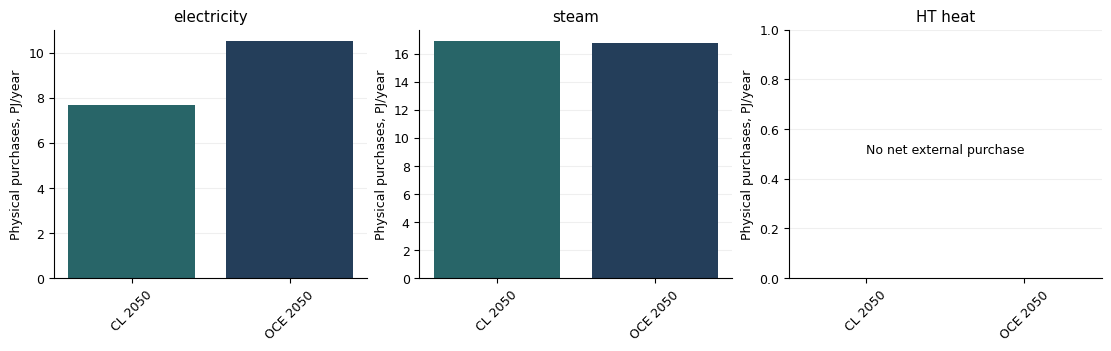

direction,scenario,year,product,output,input,import,export,residual
59,CL,2050,syngas_CO,2011.925768,2011.925768,0.0,0.0,0.000000
60,CL,2050,syngas_CO2,555.329740,555.329740,0.0,0.0,-0.000000
61,CL,2050,syngas_H2,250.371074,250.371074,0.0,0.0,0.000000
127,OCE,2050,syngas_CO,908.272629,748.485601,0.0,0.0,159.787029
128,OCE,2050,syngas_CO2,247.056242,247.056242,0.0,0.0,0.000000
129,OCE,2050,syngas_H2,105.313534,105.313534,0.0,0.0,0.000000


,,all_final_products_kt,selected_polymer_reference_kt,direct_CO2_kt
scenario,year,,,
CL,2050,1262.161,1232.161,191.158
OCE,2050,2251.115,2221.115,1836.087


In [17]:
plt.rcParams.update({"font.size":9,"axes.spines.top":False,"axes.spines.right":False})
fig, axes = plt.subplots(1,3,figsize=(11,3.4),constrained_layout=True)
for ax, product in zip(axes, ["electricity","steam","HT_heat"]):
    part = utility_balance.loc[utility_balance["product"].eq(product)]
    ax.bar(part.scenario+" "+part.year.astype(str),part.physical_purchase/1000,
           color=part.scenario.map({"CL":"#286568","OCE":"#243E5A"}).fillna("#49647A"))
    if not part.physical_purchase.gt(TOLERANCE).any():
        ax.set_ylim(0, 1)
        ax.text(0.5, 0.5, "No net external purchase", transform=ax.transAxes, ha="center")
    ax.set_title(product.replace("_"," "))
    ax.set_ylabel("Physical purchases, PJ/year")
    ax.tick_params(axis="x",rotation=45)
    ax.grid(axis="y",alpha=0.2)
    ax.set_axisbelow(True)
plt.show()
syngas_balance = product_balance.loc[product_balance["product"].isin(
    ["syngas_CO","syngas_H2","syngas_CO2"]),
    ["scenario","year","product","output","input","import","export","residual"]]
display(syngas_balance.round(6))
summary = final_basket.groupby(["scenario","year"]).basket_quantity.sum().rename("all_final_products_kt").to_frame()
summary = summary.join(final_basket.loc[final_basket.selected_reference].groupby(
    ["scenario","year"]).basket_quantity.sum().rename("selected_polymer_reference_kt"))
summary = summary.join(direct_co2.set_index(["scenario","year"]))
display(summary.round(3))


## 7. Optional background LCA

Map each external purchase to an exact Brightway provider key in a reviewed prospective database. Utilities need the right industrial grade. Imported DAC methanol needs its complete imported production chain, with atmospheric uptake characterized consistently.

The calculation combines external purchases in one demand vector and adds characterized direct emissions. This is equivalent to an annual cluster service without writing a database. Do not use the allocated domestic gasification, methanol, MTO/MTA or polymer activities as providers.

The physical export lacks some auxiliary inputs and pollutants. Complete the coverage statements before LCIA. Map unresolved CO2 origins explicitly and add other emissions where supported. A missing supplier or pollutant must not silently become zero impact.


In [18]:
BRIGHTWAY_PROJECT = "por"
LCIA_METHOD = ("EF v3.1","climate change","global warming potential (GWP100)")
# (source_id, product): (database_name, activity_code)
PROVIDER_KEYS = {}
# origin label: (biosphere_database, flow_code)
DIRECT_CO2_FLOW_KEYS = {}
# Explicitly reviewed zero factors for flows omitted from the chosen method.
VERIFIED_ZERO_FACTOR_FLOWS = set()
# (scenario, year): {"fossil": ..., "biogenic": ..., "DAC": ...}, summing to one.
DIRECT_CO2_ORIGIN_FRACTIONS = {}
# Additional records: scenario, year, flow_key, amount_kg, evidence.
ADDITIONAL_DIRECT_EXCHANGES = []
REVIEW = {
    "material_residuals_and_complete_output_basket":"",
    "utility_quality_and_procurement_adjustments":"",
    "provider_boundaries_and_source_import_overlap":"",
    "water_oxygen_catalysts_infrastructure_and_other_omissions":"",
    "transport_and_captured_CO2_destination_services":"",
    "carbon_origins_uptake_release_and_other_pollutants":"",
}
provider_review = external_inventory[["source_id","product"]].drop_duplicates().copy()
provider_review["provider_key"] = [
    PROVIDER_KEYS.get((r.source_id,r.product)) for r in provider_review.itertuples(index=False)]
display(provider_review)
print("LCIA enabled:", RUN_BACKGROUND_LCIA)
print("Reviews required:", [k for k,v in REVIEW.items() if not v.strip()])


,source_id,product,provider_key
0,import:Koeln_Nord_Dormagen_Leverkusen:RHINE_SH...,benzene,None
1,import:Koeln_Sued_Wesseling_Godorf_Luelsdorf:R...,para_xylene,None
2,import:TRANSPORT_HUB_West:OTHER,MMA,None
3,import:TRANSPORT_HUB_West:OTHER,PU_waste,None
4,import:TRANSPORT_HUB_West:OTHER,adipic_acid,None
5,import:TRANSPORT_HUB_West:OTHER,adiponitrile,None
6,import:TRANSPORT_HUB_West:OTHER,aniline,None
7,import:TRANSPORT_HUB_West:OTHER,butanediol,None
8,import:TRANSPORT_HUB_West:OTHER,cracker_HFO,None
9,import:TRANSPORT_HUB_West:OTHER,ethylene_dichloride,None


LCIA enabled: True
Reviews required: ['material_residuals_and_complete_output_basket', 'utility_quality_and_procurement_adjustments', 'provider_boundaries_and_source_import_overlap', 'water_oxygen_catalysts_infrastructure_and_other_omissions', 'transport_and_captured_CO2_destination_services', 'carbon_origins_uptake_release_and_other_pollutants']


In [19]:
cluster_lcia = None
if RUN_BACKGROUND_LCIA:
    pending = [k for k,v in REVIEW.items() if not v.strip()]
    if pending:
        raise ValueError("Complete the coverage reviews: "+", ".join(pending))
    if provider_review.provider_key.isna().any():
        raise ValueError("Every external input needs a reviewed provider.")
    import bw2data as bd
    import bw2calc as bc
    bd.projects.set_current(BRIGHTWAY_PROJECT)
    if LCIA_METHOD not in bd.methods:
        raise ValueError(f"Method not installed: {LCIA_METHOD}")
    factors = dict(bd.Method(LCIA_METHOD).load())
    for key in VERIFIED_ZERO_FACTOR_FLOWS:
        key = tuple(key)
        if key in factors and factors[key] != 0:
            raise ValueError("A verified zero factor conflicts with the installed method.")
        factors[key] = 0.0
    results = []
    for scenario in SCENARIOS:
        for year in YEARS:
            demand = {}
            for row in external_inventory.loc[external_inventory.scenario.eq(scenario)
                & external_inventory.year.eq(year)].itertuples(index=False):
                key = tuple(PROVIDER_KEYS[(row.source_id,row.product)])
                activity = bd.get_activity(key)
                if row.unit=="kt/year" and activity["unit"]=="kilogram":
                    quantity = row.quantity*1e6
                elif row.unit=="TJ/year" and activity["unit"]=="kilowatt hour":
                    quantity = row.quantity*1e6/3.6
                elif row.unit=="TJ/year" and activity["unit"]=="megajoule":
                    quantity = row.quantity*1e6
                else:
                    raise ValueError(f"Unit mismatch for {row.product}: {row.unit} -> {activity['unit']}")
                demand[activity] = demand.get(activity,0.)+quantity
            shares = DIRECT_CO2_ORIGIN_FRACTIONS.get((scenario,year),{})
            if (not shares or not all(np.isfinite(v) and 0<=v<=1 for v in shares.values())
                or not np.isclose(sum(shares.values()),1.)):
                raise ValueError(f"Review CO2 origin fractions: {scenario}/{year}")
            total_co2 = annual_inventories[f"{scenario}_{year}"]["direct_CO2_origin_unresolved_kg"]
            direct_score = 0.
            for origin, share in shares.items():
                if share==0:
                    continue
                if origin not in DIRECT_CO2_FLOW_KEYS:
                    raise ValueError(f"Missing CO2 flow key: {origin}")
                key = tuple(DIRECT_CO2_FLOW_KEYS[origin])
                if key not in factors or bd.get_activity(key)["unit"]!="kilogram":
                    raise ValueError(f"Verify the flow and explicit characterization factor: {key}")
                if not isinstance(factors[key],(int,float)):
                    raise ValueError("Scalar characterization factors required.")
                direct_score += total_co2*share*factors[key]
            for extra in ADDITIONAL_DIRECT_EXCHANGES:
                if extra["scenario"]==scenario and extra["year"]==year:
                    key = tuple(extra["flow_key"])
                    if key not in factors or not extra["evidence"].strip():
                        raise ValueError("Additional direct flows need evidence and characterization.")
                    amount = float(extra["amount_kg"])
                    if not np.isfinite(amount):
                        raise ValueError("Invalid additional direct flow.")
                    direct_score += amount*factors[key]
            lca = bc.LCA(demand,LCIA_METHOD)
            lca.lci()
            lca.lcia()
            results.append(dict(scenario=scenario,year=year,method=str(LCIA_METHOD),
                external_supply_score=float(lca.score),direct_score=direct_score,
                annual_cluster_score=float(lca.score)+direct_score))
    cluster_lcia = pd.DataFrame(results)
    display(cluster_lcia)
else:
    print("Physical inventories assembled. Complete supply and emission review before calculating LCIA.")


ValueError: Complete the coverage reviews: material_residuals_and_complete_output_basket, utility_quality_and_procurement_adjustments, provider_boundaries_and_source_import_overlap, water_oxygen_catalysts_infrastructure_and_other_omissions, transport_and_captured_CO2_destination_services, carbon_origins_uptake_release_and_other_pollutants

## 8. Optional exports and next steps

SAVE_OUTPUTS writes audit tables, physical inventories and source hashes into a new run folder. It does not edit existing files. Source raw-aromatic labels are retained here, without applying the downstream YAML's terminal-purity reconciliation.

The complete annual basket includes intermediate exports as well as final products. It is not functionally equivalent to another scenario merely because total tonnes are comparable. A fixed selected-polymer basket needs a separate determination of required process activity and coproduct destinations.

A full carbon balance requires carbon fractions and origins for inputs, products, wastes and emissions. Recycled fossil-plastic carbon remains fossil. No extra uptake or avoided-incineration credit is inferred.

Next, review the scope, resolve residuals and utility quality, add missing physical burdens, map prospective background providers, and review CO2 origins. The result can then be compared to the existing allocated polymer footprint after reconciling coverage.

Methodological references include the [JRC ILCD handbook](https://publications.jrc.ec.europa.eu/repository/bitstream/JRC48157/ilcd_handbook-general_guide_for_lca-detailed_guidance_12march2010_isbn_fin.pdf), [ecoinvent system models](https://support.ecoinvent.org/system-models) and [ecoinvent carbon guidance](https://support.ecoinvent.org/guidance-on-ipcc-methods).


In [ ]:
if SAVE_OUTPUTS:
    folder = OUTPUT_DIR/datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    folder.mkdir(parents=True,exist_ok=False)
    for name, table in {
        "physical_ledger":ledger,"border_trade":trade,"product_balance":product_balance,
        "utility_balance":utility_balance,"final_basket":final_basket,
        "exported_products":exported_products,"CO2_streams":co2_balance,
        "external_inventory":external_inventory,"activity_checks":activity_checks,
        "missing_factors":missing_factors,"unresolved_balances":unresolved,
        "filtered_bookkeeping":filtered_bookkeeping,"provider_review":provider_review,
        "boundary_review":boundary_table,
    }.items():
        table.to_csv(folder/f"{name}.csv",index=False)
    manifest = dict(
        sources=provenance,scenarios=SCENARIOS,years=YEARS,location=LOCATION,
        period_years=PERIOD_YEARS,functional_unit="one complete annual conversion-cluster basket",
        allocation_of_internal_intermediates=False,boundary_overrides=BOUNDARY_OVERRIDES,
        utility_rule="net included demand after same-class generation",coverage_review=REVIEW,
        background_lcia_calculated=cluster_lcia is not None,method=list(LCIA_METHOD),
        providers=[dict(source_id=k[0],product=k[1],key=list(v)) for k,v in PROVIDER_KEYS.items()])
    (folder/"manifest.json").write_text(json.dumps(manifest,indent=2),encoding="utf-8")
    (folder/"annual_cluster_inventories.json").write_text(
        json.dumps(annual_inventories,indent=2),encoding="utf-8")
    if cluster_lcia is not None:
        cluster_lcia.to_csv(folder/"cluster_lcia.csv",index=False)
    print("Saved",folder)
